# Shutdown Dose Rate (SDDR) Analysis for Spherical Tokamak Fusion Reactor

## Notebook-4
This notebook calculates the shutdown dose rate (SDDR), which is the gamma radiation emitted by activated materials after a fusion reactor is shut down. The decay of the activated materials from the Depletion and Activation notebook (one full year at 1 MW/m² wall loading, 62.7 MW of fusion power) is used as a gamma source. The photons are tracked through the same spherical-tokamak model with OpenMC, and the photon flux is converted to dose with ICRP-116 coefficients.

The dose rate is given in mSv/h in two forms. The first is an average for each component, which is used to compare the components. The second is a dose map across the machine, including the empty vessel, which is the place where people or remote tools would work. Three cooldown times are covered: 0 d (shutdown), 1 d and 7 d.


## Methodology

The notebook follows the Rigorous 2-Step (R2S) method. Neutron transport and activation (Step 1) are covered in the `Depletion and Activation Notebook`. This notebook performs Step 2:

1. **Load the decay composition.** The decay composition at the selected cooldown time is loaded from `depletion_results.h5`. The `shutdown_step` variable selects the time: 1 (0 d), 2 (1 d) or 3 (7 d). All nuclides are retained to avoid losing gamma emitters without neutron cross-section data.

2. **Gamma sources.** Each of the six solid components is modelled as a volumetric, isotropic gamma source, using its own decay-photon spectrum and normalised photon emission rate (photons/s).

3. **Photon transport.** Photons are transported through the same model using the original, non-activated materials.

4. **Dose calculation.** Photon flux is converted to effective dose using the ICRP-116 flux-to-dose coefficients, with tallies in each cell and across an x–z mesh.

5. **Dose normalisation.** The source-normalised results are scaled by the total photon emission rate, divided by volume and converted from pSv/s to mSv/h.

6. **Cooldown comparison.** The calculation is repeated for all three cooldown times (0, 1 and 7 days), and the results are compared.

## Input data

* `config.py`: the nuclear data library, `MODEL_NAME` and `BASE_DIR`.
* `materials.xml`, `geometry.xml`, `settings.xml` and `geometry_dimensions.csv` in the base configuration folder. The volumes are taken from `geometry_dimensions.csv`.
* `depletion_results.h5` from the Depletion and Activation notebook.
* The depletion chain file (`chain_fendl30_fusion_complete.xml`). It holds the decay-photon spectra, so it must be set in the configuration.

## Outputs and main results

For each cooldown step, the notebook saves component-wise dose rates, attenuation plots, dose maps, statepoints and settings in `Spherical_tokamak_fendl_SDDR`. It also generates a combined CSV file and cooldown comparison plot.

The main observations are:

- The **First Wall** has the highest dose rate, followed by the **Protective Shield**. Together with the breeding blanket, these components account for approximately 98% of the total photon emission at 1 day, mainly from activated tungsten products.
- The dose rate decreases significantly with cooldown time, by factors of approximately 18 for the First Wall and 55 for the Copper Magnet Rod between shutdown and 7 days. The reflector shows a rapid initial decrease due to Mn-56, followed by a slower decay dominated by Co-60, Fe-59 and Cr-51.
- The statistical uncertainty in the component-averaged dose rates is below 1% in the 1-day calculation.
- The dose map shows approximately \(10^6\) mSv/h in the empty vessel region after 1 day, close to the First Wall dose rate. This is far above the commonly used hands-on maintenance design target of 10 µSv/h, indicating that maintenance inside the vessel would require remote handling.


## Modelling Assumptions and Limitations

- Component-averaged dose rates represent the dose within the activated materials, not the dose received by personnel or equipment in the vessel.
- Each component is modelled with a uniform activity distribution. In reality, activation is higher near the plasma-facing surfaces, which may lead to an underestimation of the vessel dose.
- The analysis considers only one year of continuous full-power operation, rather than realistic pulsed operation over several years.
- Dose conversion uses ICRP-116 effective dose coefficients for front-to-back irradiation. Other studies may use ambient dose equivalent, H*(10).
- The dose map covers only a 20 cm slice up to 350 cm and excludes the biological shield and cryostat. It therefore does not represent the dose outside the machine.
- Low-energy tungsten X-rays are largely absorbed within the tungsten, resulting in fewer photons reaching the outer layers and increased statistical noise in the dose map.
  
## References

1. Y. Chen and U. Fischer, "Rigorous MCNP based shutdown dose rate calculations: computational scheme, verification calculations and application to ITER", *Fusion Engineering and Design* 63–64 (2002) 107–114.
2. U. Fischer, D. Leichtle, A. Serikov, P. Pereslavtsev and R. Villari, "Shutdown dose rate calculations for ITER: R2S, R2Smesh and D1S", *Fusion Science and Technology* 64(3) (2013) 563–570. https://doi.org/10.13182/FST13-A19153
3. ICRP, *Conversion Coefficients for Radiological Protection Quantities for External Radiation Exposures*, ICRP Publication 116, Annals of the ICRP 40(2–5) (2010). https://icrpaedia.org/ICRP_Publication_116
4. OpenMC dose coefficients: https://docs.openmc.org/en/stable/pythonapi/generated/openmc.data.dose_coefficients.html
5. P. K. Romano et al., "OpenMC: A state-of-the-art Monte Carlo code for research and development", *Annals of Nuclear Energy* 82 (2015) 90–97. https://doi.org/10.1016/j.anucene.2014.07.048

In [2]:
import openmc
import openmc.deplete

import matplotlib.pyplot as plt
import os
import math
import openmc.stats
import numpy as np
import pandas as pd
import os

from config import data_library, prefix, MODEL_NAME, BASE_DIR



In [3]:
print(MODEL_NAME)
print(BASE_DIR)

DEPLETION_DIR = f"./{MODEL_NAME}_Depletion+Activation"
print(DEPLETION_DIR)

shutdown_step = 2      # <-- CHANGE THIS: 1 = end of irradiation (0 d), 2 = after 1 day, 3 = after 7 days


SDDR_DIR = f"./{MODEL_NAME}_SDDR"
os.makedirs(SDDR_DIR, exist_ok=True)

RESULTS_DIR = os.path.join(SDDR_DIR, f"{MODEL_NAME}_SDDR_step{shutdown_step}")      
os.makedirs(RESULTS_DIR, exist_ok=True)

print(SDDR_DIR)
print(RESULTS_DIR)

Spherical_tokamak_fendl
./Spherical_tokamak_fendl_Basic_Configuration
./Spherical_tokamak_fendl_Depletion+Activation
./Spherical_tokamak_fendl_SDDR
./Spherical_tokamak_fendl_SDDR/Spherical_tokamak_fendl_SDDR_step2


In [4]:
depletion_chain = "/workspace/chain/chain_fendl30_fusion_complete.xml"

if os.path.exists(depletion_chain):
    print("Chain file exists!")
    print(f"Path to chain file: {depletion_chain}")
    openmc.config['chain_file'] = depletion_chain
else:
    print("Chain file not found.")

Chain file exists!
Path to chain file: /workspace/chain/chain_fendl30_fusion_complete.xml


# Extract and Load the Activated Materials

The activated inventory at the chosen cooldown step (`shutdown_step`) is read from `depletion_results.h5`. All tracked nuclides are kept. The photon transport itself uses the ordinary, un-activated materials from `materials.xml`. The activated materials are used only to define the photon sources.

In [4]:
results_path = os.path.join(DEPLETION_DIR, 'depletion_results.h5')
original_mats_path = os.path.join(BASE_DIR, 'materials.xml')

openmc.reset_auto_ids()

results = openmc.deplete.Results(results_path)

nuc_all = list(results[0].index_nuc)
activated_materials = results.export_to_materials(shutdown_step, nuc_with_data=nuc_all, path=original_mats_path)

# For the photon TRANSPORT use the ordinary (un-activated) materials
materials = openmc.Materials.from_xml(original_mats_path)

/usr/local/lib/python3.12/dist-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=1.
  warn(msg, IDWarning)
/usr/local/lib/python3.12/dist-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=2.
  warn(msg, IDWarning)
/usr/local/lib/python3.12/dist-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=3.
  warn(msg, IDWarning)
/usr/local/lib/python3.12/dist-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=4.
  warn(msg, IDWarning)
/usr/local/lib/python3.12/dist-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=5.
  warn(msg, IDWarning)
/usr/local/lib/python3.12/dist-packages/openmc/mixin.py:72: IDWarning: Another Material instance already exists with id=8.
  warn(msg, IDWarning)


# Load Geometry and Link to Activated Materials

The geometry is loaded and each activated material is linked to its component by cell name. The radii and the analytic volumes are read from `geometry_dimensions.csv`.

In [5]:
geometry = openmc.Geometry.from_xml(os.path.join(BASE_DIR, 'geometry.xml'), materials=materials)
openmc.reset_auto_ids()    # to prrevent all the warnings

# Re-link the Python variables to the loaded cells using exact names
all_cells = geometry.get_all_cells()
cell_cu = next(c for c in all_cells.values() if c.name == 'Copper Magnet Rod')
cell_shield = next(c for c in all_cells.values() if c.name == 'Protective Shield')
cell_fw = next(c for c in all_cells.values() if c.name == 'First Wall')
cell_blanket = next(c for c in all_cells.values() if c.name == 'Breeding Blanket')
cell_mirror = next(c for c in all_cells.values() if c.name == 'Reflector')
cell_outer = next(c for c in all_cells.values() if c.name == 'Outer Shield')
# skipping plasma and vacuum


# Extracting the specific Activated materials sitting inside those cells (used only for the photon source)
fw_mat = next(m for m in activated_materials if m.id == cell_fw.fill.id)
shield_mat = next(m for m in activated_materials if m.id == cell_shield.fill.id)
blanket_mat = next(m for m in activated_materials if m.id == cell_blanket.fill.id)
mirror_mat = next(m for m in activated_materials if m.id == cell_mirror.fill.id)
cu_mat = next(m for m in activated_materials if m.id == cell_cu.fill.id)

outer_mat = next(m for m in activated_materials if m.id == cell_outer.fill.id)

In [6]:
geom_df = pd.read_csv(os.path.join(BASE_DIR, 'geometry_dimensions.csv'), index_col="Component")

def dim(name, col):
    return float(geom_df.loc[name, col])

# Radii (cm)
r_cu_in       = dim("Copper Magnet Rod (Central)",  "Inner Radius (cm)")
r_cu_out      = dim("Copper Magnet Rod (Central)",  "Outer Radius (cm)")
r_shield_in   = dim("Protective Shield (Central)",  "Inner Radius (cm)")
r_shield_out  = dim("Protective Shield (Central)",  "Outer Radius (cm)")
r_fw_in       = dim("First Wall (Spherical)",       "Inner Radius (cm)")
r_fw_out      = dim("First Wall (Spherical)",       "Outer Radius (cm)")
r_blanket_in  = dim("Breeding Blanket (Spherical)", "Inner Radius (cm)")
r_blanket_out = dim("Breeding Blanket (Spherical)", "Outer Radius (cm)")
r_mirror_in   = dim("Steel Reflector (Spherical)",  "Inner Radius (cm)")
r_mirror_out  = dim("Steel Reflector (Spherical)",  "Outer Radius (cm)")
r_outer_in    = dim("Outer Shield (Spherical)",     "Inner Radius (cm)")
r_outer_out   = dim("Outer Shield (Spherical)",     "Outer Radius (cm)")

# The central column (Cu rod + shield) is capped by the outermost sphere,
# so its half-length equals that radius
z_bound = r_outer_out

# The spherical shells must touch each other
assert np.isclose(r_fw_out, r_blanket_in) and np.isclose(r_blanket_out, r_mirror_in) \
   and np.isclose(r_mirror_out, r_outer_in), "shell radii not contiguous - check geometry_dimensions.csv"

# Analytic volumes (cm^3)
vol_cu      = dim("Copper Magnet Rod (Central)",  "Volume (cm^3)")
vol_shield  = dim("Protective Shield (Central)",  "Volume (cm^3)")
vol_fw      = dim("First Wall (Spherical)",       "Volume (cm^3)")
vol_blanket = dim("Breeding Blanket (Spherical)", "Volume (cm^3)")
vol_mirror  = dim("Steel Reflector (Spherical)",  "Volume (cm^3)")
vol_outer   = dim("Outer Shield (Spherical)",     "Volume (cm^3)")

print(geom_df[['Inner Radius (cm)', 'Outer Radius (cm)', 'Volume (cm^3)']])
print(f"Column half-length z_bound = {z_bound} cm")

                             Inner Radius (cm)        Outer Radius (cm)  \
Component                                                                 
Copper Magnet Rod (Central)                0.0                     20.0   
Protective Shield (Central)               23.0                     53.0   
First Wall (Spherical)                   200.0                    201.0   
Breeding Blanket (Spherical)             201.0                    301.0   
Steel Reflector (Spherical)              301.0                    321.0   
Outer Shield (Spherical)                 321.0                    351.0   
Plasma Torus                    Major a: 126.5  Minor b: 100.0, c: 50.0   

                              Volume (cm^3)  
Component                                    
Copper Magnet Rod (Central)    8.814428e+05  
Protective Shield (Central)    4.994114e+06  
First Wall (Spherical)         4.872032e+05  
Breeding Blanket (Spherical)   7.843064e+07  
Steel Reflector (Spherical)    2.396142e+07  
Ou

# SDDR Methodology and Multi-Component Photon Sources

## The Rigorous 2-Step (R2S) Workflow
During reactor operation, fusion neutrons cause nuclear reactions in the structural materials and create unstable isotopes. When the plasma stops, the prompt radiation stops. The remaining radiation field comes only from the decay of these activated isotopes. The first step, which was done in the Depletion and Activation notebook, followed the materials through one year of operation and the cooldown. This second step takes that isotopic inventory as a volumetric fixed photon source for a separate gamma-transport calculation.

## Component sources  

* **First wall and protective shield:** Tungsten products dominate. W-185 has the highest activity (2.6 × 10¹² Bq/cm³ in the first wall and 1.7 × 10¹¹ Bq/cm³ in the shield), followed by W-181 and W-187. W-185 is almost a pure beta emitter, so most of the photons come from W-181 (tantalum X-rays), W-187, Re-186, Ta-182 and Re-184.
* **Steel reflector:** Mn-56 (2.9 × 10⁹ Bq/cm³, half-life 2.6 h) is the largest at shutdown. Cr-51, Fe-59 and the long-lived Co-60 are the main ones later.
* **Copper rod:** Cu-64 (5.3 × 10⁹ Bq/cm³, half-life 12.7 h) is the largest at shutdown. Co-60 takes over after a few days.
* **Breeding blanket:** Tritium is the most active (2.0 × 10¹⁰ Bq/cm³), but it is a pure beta emitter and gives no gamma rays. The main gamma emitters are Pb-203 (2.4 × 10⁹ Bq/cm³) and Pb-209 (1.2 × 10⁹ Bq/cm³).
* **Outer shield:** W-187 (4.1 × 10⁸ Bq/cm³) and W-185.

In the saved 1-day run, the first wall, the protective shield and the blanket gave around 98 % of all photons. The reflector, the outer shield and the copper rod emitted much less. They are still included, so that the comparison of the components is complete and the dose near the outside of the machine is not under-estimated. Photons are sampled from the whole geometry using `openmc.IndependentSource`.

## Source Strength Normalisation
`get_activity()` gives the number of decays per second and per cm³, which is not as same as the number of photons, since a decay can give no photon or several photons. For the transport source photon emission rate in photons/s is required. It is found with `get_decay_photon_energy(units='Bq', volume=V)`. This function is given the exact analytic cell volume, so its `.integral()` is already the photon rate of the whole component.

OpenMC uses the strengths of several sources as relative weights. They are set to the share of each component in the total photon rate, so that they add up to 1.0. The Monte Carlo tally is then calculated **per source photon**. To get the absolute dose rate (mSv/h), the tally is multiplied by `total_photon_rate` in the post-processing step.

## Cooldown Steps and Dose Mapping
The notebook is run once for each cooldown step: immediately at shutdown (0 days, `shutdown_step = 1`), after 1 day (`shutdown_step = 2`) and after 7 days (`shutdown_step = 3`). The photon flux is tallied in every cell, and also on a regular mesh in the x–z plane (200 × 1 × 200 bins, 20 cm thick in y). It is converted to dose with the ICRP-116 coefficients. This gives a two-dimensional dose map of a slice through the machine.

In [7]:
# One table drives photon rates, sources, volumes and the results table
components = {
    'First Wall':        dict(cell=cell_fw,      mat=fw_mat,      vol=vol_fw,      r=(r_fw_in,      r_fw_out),      shape='shell'),
    'Protective Shield': dict(cell=cell_shield,  mat=shield_mat,  vol=vol_shield,  r=(r_shield_in,  r_shield_out),  shape='column'),
    'Breeding Blanket':  dict(cell=cell_blanket, mat=blanket_mat, vol=vol_blanket, r=(r_blanket_in, r_blanket_out), shape='shell'),
    'Reflector':         dict(cell=cell_mirror,  mat=mirror_mat,  vol=vol_mirror,  r=(r_mirror_in,  r_mirror_out),  shape='shell'),
    'Copper Magnet Rod': dict(cell=cell_cu,      mat=cu_mat,      vol=vol_cu,      r=(r_cu_in,      r_cu_out),      shape='column'),
    'Outer Shield':      dict(cell=cell_outer,   mat=outer_mat,   vol=vol_outer,   r=(r_outer_in,   r_outer_out),   shape='shell'),
}

# True decay-photon emission rate (photons/s), not decays/s
for comp in components.values():
    comp['photons'] = comp['mat'].get_decay_photon_energy(units='Bq', volume=comp['vol'])
    comp['rate']    = comp['photons'].integral()

total_photon_rate = sum(comp['rate'] for comp in components.values())

for name, comp in components.items():
    print(f"{name:18s}: {comp['rate']:.3e} photons/s")
print(f"{'Total':18s}: {total_photon_rate:.3e} photons/s")

First Wall        : 8.756e+17 photons/s
Protective Shield : 5.474e+17 photons/s
Breeding Blanket  : 2.911e+17 photons/s
Reflector         : 1.806e+16 photons/s
Copper Magnet Rod : 6.707e+14 photons/s
Outer Shield      : 1.070e+16 photons/s
Total             : 1.744e+18 photons/s


# Decay-Photon Source Definition for the Activated Components

Each activated solid component is turned into a volumetric, isotropic gamma source. The source describes **where** the photons are born (space distribution), **how many** each component emits (relative strength) and **at what energies** (decay-photon spectrum from the depletion results). The six sources are passed together to the photon-transport run.

**Source strength.** `get_decay_photon_energy(units='Bq', volume=V)` is given the volume $V_i$ of the component, so its integral is already the emission rate of the whole component, $S_i$ (photons/s). OpenMC uses the strengths of several sources as relative weights, so each source gets

$$w_i=\frac{S_i}{\sum_j S_j},\qquad \sum_i w_i = 1,$$

and the tally is then calculated **per source photon**. The absolute dose rate is found later by multiplying with $S_{tot}=\sum_j S_j$ (`total_photon_rate`).

**Energy distribution.** Each source uses the decay-photon spectrum of its own activated material (mostly discrete lines, with X-rays). The mix of tungsten, copper, steel and lead nuclides is therefore reflected in the photon energies. The spectrum is that of the chosen cooldown step.

Each block below defines one source in the order *First Wall, Protective Shield, Breeding Blanket, Reflector, Copper Magnet Rod, Outer Shield*. It uses the radii and `z_bound` from the geometry cell and the rates from the `components` table. The last lines collect the sources and check that the strengths add up to 1.0.

In [8]:
# First Wall photon source (spherical shell, uniform in volume: pdf proportional to r^2)
source_fw = openmc.IndependentSource(
    space=openmc.stats.SphericalIndependent(
        r=openmc.stats.PowerLaw(a=r_fw_in, b=r_fw_out, n=2),
        cos_theta=openmc.stats.Uniform(a=-1.0, b=1.0),
        phi=openmc.stats.Uniform(a=0, b=2 * math.pi)
    ),
    energy=components['First Wall']['photons'],
    particle='photon',
    strength=components['First Wall']['rate'] / total_photon_rate,
    constraints={'domains': [cell_fw]}                # rejects points inside the central column
)

# Protective Shield photon source (central column, cylindrical, uniform in area: pdf proportional to r)
source_shield = openmc.IndependentSource(
    space=openmc.stats.CylindricalIndependent(
        r=openmc.stats.PowerLaw(a=r_shield_in, b=r_shield_out, n=1),
        phi=openmc.stats.Uniform(a=0, b=2 * math.pi),
        z=openmc.stats.Uniform(a=-z_bound, b=z_bound)
    ),
    energy=components['Protective Shield']['photons'],
    particle='photon',
    strength=components['Protective Shield']['rate'] / total_photon_rate,
    constraints={'domains': [cell_shield]}
)

# Breeding Blanket photon source (spherical shell, uniform in volume)
source_blanket = openmc.IndependentSource(
    space=openmc.stats.SphericalIndependent(
        r=openmc.stats.PowerLaw(a=r_blanket_in, b=r_blanket_out, n=2),
        cos_theta=openmc.stats.Uniform(a=-1.0, b=1.0),
        phi=openmc.stats.Uniform(a=0, b=2 * math.pi)
    ),
    energy=components['Breeding Blanket']['photons'],
    particle='photon',
    strength=components['Breeding Blanket']['rate'] / total_photon_rate,
    constraints={'domains': [cell_blanket]}
)

# Steel Reflector photon source (spherical shell, uniform in volume)
source_mirror = openmc.IndependentSource(
    space=openmc.stats.SphericalIndependent(
        r=openmc.stats.PowerLaw(a=r_mirror_in, b=r_mirror_out, n=2),
        cos_theta=openmc.stats.Uniform(a=-1.0, b=1.0),
        phi=openmc.stats.Uniform(a=0, b=2 * math.pi)
    ),
    energy=components['Reflector']['photons'],
    particle='photon',
    strength=components['Reflector']['rate'] / total_photon_rate,
    constraints={'domains': [cell_mirror]}
)

# Copper Magnet Rod photon source (central column, cylindrical, uniform in area)
source_cu = openmc.IndependentSource(
    space=openmc.stats.CylindricalIndependent(
        r=openmc.stats.PowerLaw(a=r_cu_in, b=r_cu_out, n=1),
        phi=openmc.stats.Uniform(a=0, b=2 * math.pi),
        z=openmc.stats.Uniform(a=-z_bound, b=z_bound)
    ),
    energy=components['Copper Magnet Rod']['photons'],
    particle='photon',
    strength=components['Copper Magnet Rod']['rate'] / total_photon_rate,
    constraints={'domains': [cell_cu]}
)

# Outer Shield photon source (spherical shell, uniform in volume)
source_outer = openmc.IndependentSource(
    space=openmc.stats.SphericalIndependent(
        r=openmc.stats.PowerLaw(a=r_outer_in, b=r_outer_out, n=2),
        cos_theta=openmc.stats.Uniform(a=-1.0, b=1.0),
        phi=openmc.stats.Uniform(a=0, b=2 * math.pi)
    ),
    energy=components['Outer Shield']['photons'],
    particle='photon',
    strength=components['Outer Shield']['rate'] / total_photon_rate,
    constraints={'domains': [cell_outer]}
)

sources = [source_fw, source_shield, source_blanket, source_mirror, source_cu, source_outer]
print("Sum of source strengths:", sum(s.strength for s in sources))     # must be 1.0

Sum of source strengths: 1.0


# Settings

The base settings are loaded and changed for a fixed-source photon run. Photon transport is on, the sources are the six components, and there are 100 batches of 500,000 photons. No inactive batches are needed in a fixed-source run.

In [9]:

settings = openmc.Settings.from_xml(os.path.join(BASE_DIR, 'settings.xml'))

settings.run_mode = "fixed source"

settings.photon_transport = True

# Multi-component gamma sources
settings.source = sources

settings.batches = 100
settings.particles = 500000  
settings.inactive = 0

#settings.max_lost_particles = 50000

settings.export_to_xml(os.path.join(RESULTS_DIR, 'settings.xml'))

# `Setting up the Biological Dose Tally (ICRP-116)`

The tally scores the photon `flux` (the track length per source photon, in cm) and multiplies it by a dose coefficient that depends on the photon energy. The coefficients are the ICRP-116 effective-dose values for photons with front-to-back (AP) irradiation, given in pSv·cm^2. Two tallies use the same coefficients:

* **Cell tally:** the dose averaged over every cell. The result is in pSv·cm^3 per source photon.
* **Mesh tally:** a regular mesh of 200 × 1 × 200 bins from −350 to 350 cm in x and z, and −10 to 10 cm in y. Each bin is 3.5 × 20 × 3.5 cm (245 cm^3). It gives the dose map.

In [10]:
tallies = openmc.Tallies()

# Load built-in ICRP-116 flux-to-dose conversion factors (AP geometry, photons)
# Converts particle flux directly into dose rate (pico-Sieverts per second)
energy_bins, dose_coeffs = openmc.data.dose_coefficients(particle='photon', geometry='AP')
dose_filter = openmc.EnergyFunctionFilter(energy_bins, dose_coeffs)

# Measure the dose across every cell in the reactor
cell_filter = openmc.CellFilter(list(all_cells.values()))

dose_tally = openmc.Tally(name="SDDR_Dose_Rate")
dose_tally.filters = [cell_filter, dose_filter]
dose_tally.scores = ['flux']
tallies.append(dose_tally)

mesh = openmc.RegularMesh()
mesh.dimension = [200, 1, 200]
mesh.lower_left = [-350.0, -10.0, -350.0]
mesh.upper_right = [350.0, 10.0, 350.0]

dose_mesh_tally = openmc.Tally(name="SDDR_Dose_Map")
dose_mesh_tally.filters = [openmc.MeshFilter(mesh), dose_filter]     # same ICRP-116 dose_filter as above
dose_mesh_tally.scores = ['flux']
tallies.append(dose_mesh_tally)


# `SDDR Simulation`

The photon-transport run is started for the chosen cooldown step. The statepoint, the settings and all later results are saved in the folder of that step.

In [11]:

model = openmc.Model(geometry=geometry, materials=materials, settings=settings, tallies=tallies)

# Run and output the statepoint file into the results directory
model.run(cwd=RESULTS_DIR)

print(f"\nSDDR simulation complete. Statepoint saved in {RESULTS_DIR}")

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

# `Results Extraction`

The tally results are read from the statepoint, restricted to the six solid components, and given names and volumes. The statistical error is found for each component.

In [12]:
# Cells/Geometry structures considered for the study
target_cells = [comp['cell'] for comp in components.values()]


# Statepoint file
sp_path = os.path.join(RESULTS_DIR, f'statepoint.{settings.batches}.h5')

sp = openmc.StatePoint(sp_path)

# SDDR Dose Tally Extraction
dose_tally = sp.get_tally(name="SDDR_Dose_Rate")
df_tally = dose_tally.get_pandas_dataframe()

# Dataframe filtration to include only the target solid components
target_ids = [c.id for c in target_cells]
df_tally = df_tally[df_tally['cell'].isin(target_ids)].copy()


# Maping exact cell ids to component names for display
cell_id_to_name = {comp['cell'].id: comp['cell'].name for comp in components.values()}

df_tally['Cell Name'] = df_tally['cell'].map(cell_id_to_name)

# Volume Extraction

cell_id_to_vol = {comp['cell'].id: comp['vol'] for comp in components.values()}

df_tally['Volume (cm^3)'] = df_tally['cell'].map(cell_id_to_vol)

# Dose Rate Conversion

`Unit progression: (pSv·cm³ per source photon) × (source photons/s) ÷ (cm³) = pSv/s`

`pSv/s × 3600 (s/h) × 10⁻⁹ (mSv/pSv) = mSv/h`

In [13]:
conversion_factor = 3600 * 1e-9

df_tally['Dose Rate (mSv/hr)'] = (df_tally['mean'] * total_photon_rate / df_tally['Volume (cm^3)']) * conversion_factor
df_tally['Absolute Error (mSv/hr)'] = (df_tally['std. dev.'] * total_photon_rate / df_tally['Volume (cm^3)']) * conversion_factor

df_tally['Statistical Error (%)'] = (df_tally['std. dev.'] / df_tally['mean']) * 100


final_columns = ['Cell Name', 'Volume (cm^3)', 'Dose Rate (mSv/hr)', 'Absolute Error (mSv/hr)', 'Statistical Error (%)']
df_safety_table = df_tally[final_columns].copy()


df_safety_table.to_csv(os.path.join(RESULTS_DIR, 'sddr_table.csv'), index=False)


print("Component-Averaged Biological Dose Rates (SDDR)")
display(df_safety_table)

# Sorting by highest dose rate 
df_safety_table_1 = df_safety_table.sort_values(by='Dose Rate (mSv/hr)', ascending=False).reset_index(drop=True)
display(df_safety_table_1)


Component-Averaged Biological Dose Rates (SDDR)


,Cell Name,Volume (cm^3),Dose Rate (mSv/hr),Absolute Error (mSv/hr),Statistical Error (%)
0,Copper Magnet Rod,8.814428e+05,2.939624e+04,239.876969,0.816012
1,Protective Shield,4.994114e+06,2.291320e+05,213.937504,0.093369
2,First Wall,4.872032e+05,1.351966e+06,978.082609,0.072345
3,Breeding Blanket,7.843064e+07,5.560562e+03,6.460100,0.116177
4,Reflector,2.396142e+07,1.558323e+04,55.947321,0.359023
5,Outer Shield,4.205624e+07,1.106310e+03,3.684043,0.333003


,Cell Name,Volume (cm^3),Dose Rate (mSv/hr),Absolute Error (mSv/hr),Statistical Error (%)
0,First Wall,4.872032e+05,1.351966e+06,978.082609,0.072345
1,Protective Shield,4.994114e+06,2.291320e+05,213.937504,0.093369
2,Copper Magnet Rod,8.814428e+05,2.939624e+04,239.876969,0.816012
3,Reflector,2.396142e+07,1.558323e+04,55.947321,0.359023
4,Breeding Blanket,7.843064e+07,5.560562e+03,6.460100,0.116177
5,Outer Shield,4.205624e+07,1.106310e+03,3.684043,0.333003


# Dose Rate by Component (Log Scale)

The bar chart compares the dose rate averaged over each component, with the statistical error shown as error bars (they are too small to see in the saved run). A logarithmic scale is used because the values differ by several orders of magnitude. In the saved 1-day run the order is: first wall, protective shield, copper rod, reflector, blanket and outer shield.

This chart compares components. It is not a radial attenuation curve. The radial behaviour is shown by the midplane profile in the dose map below.

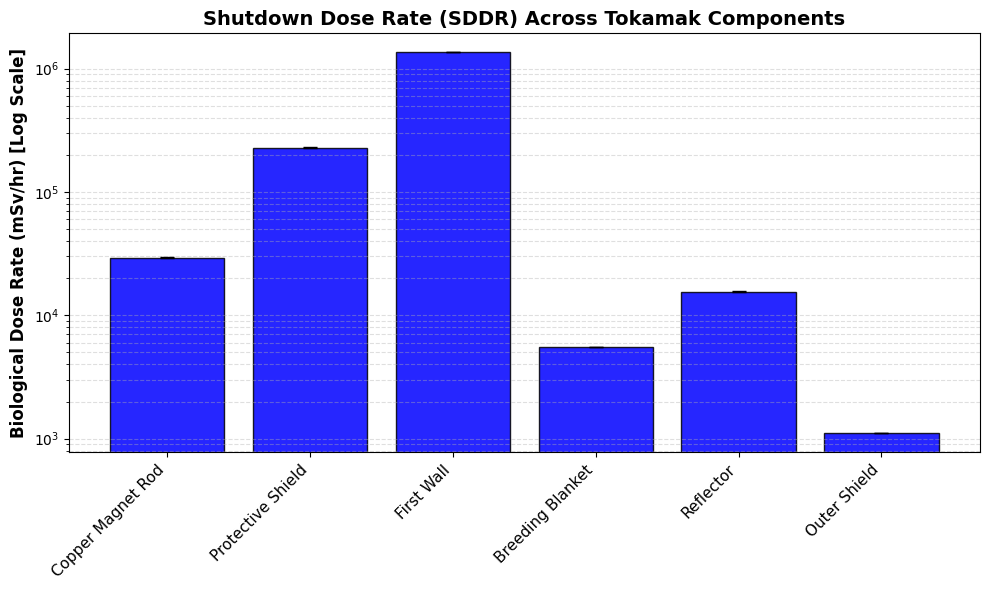

In [14]:
df_plot = df_safety_table.copy()
plt_type = 'log'  #'log' or 'linear'
plt.figure(figsize=(10, 6))

# Using a log scale because dose drops exponentially through shielding
plt.bar(df_plot['Cell Name'], df_plot['Dose Rate (mSv/hr)'], 
        yerr=df_plot['Absolute Error (mSv/hr)'], capsize=5, 
        color='blue', edgecolor='black', alpha=0.85)

plt.yscale(plt_type)
plt.ylabel('Biological Dose Rate (mSv/hr) [Log Scale]', fontsize=12, fontweight='bold')
plt.title('Shutdown Dose Rate (SDDR) Across Tokamak Components', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.grid(axis='y', which='both', linestyle='--', alpha=0.4)

# Save report-ready PNG
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f"sddr_attenuation_plot_{plt_type}.png"), dpi=300, bbox_inches='tight')
plt.show()



## SDDR Map
The component-averaged dose represents the dose inside the activated material, whereas the dose map shows the spatial distribution across the machine, including the empty vessel where maintenance would take place.

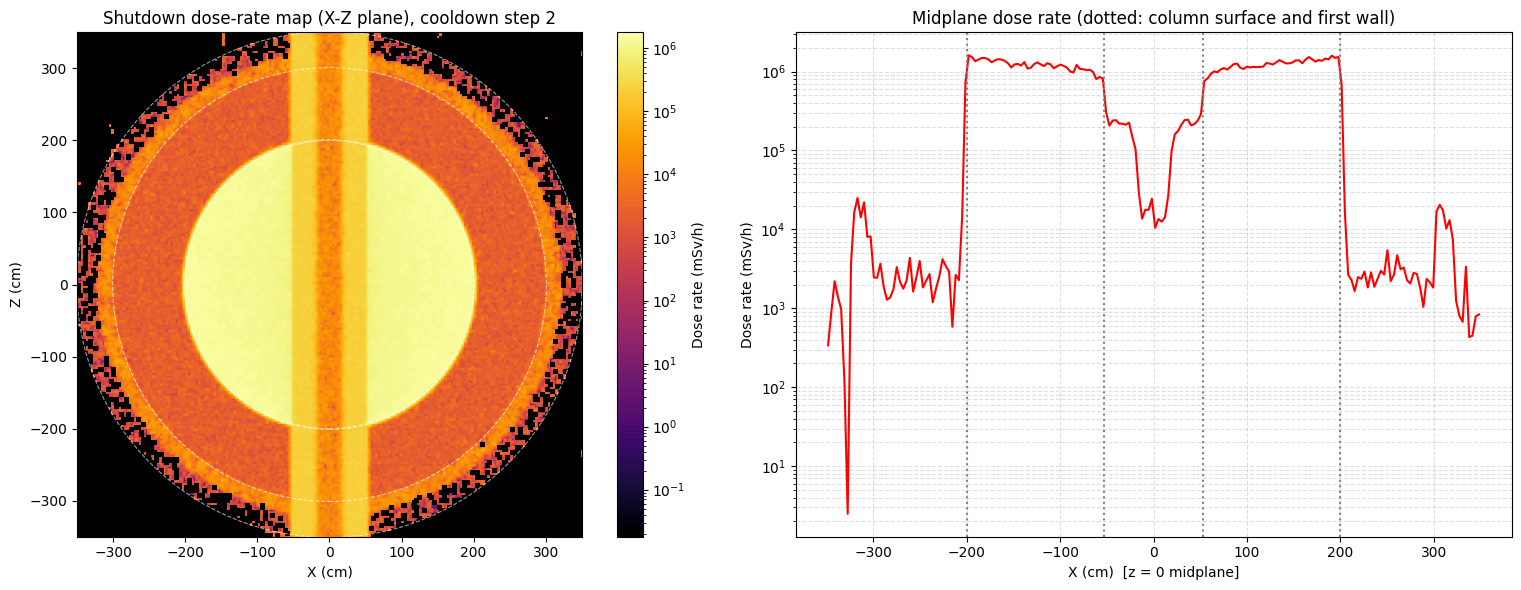

In [15]:
from matplotlib.colors import LogNorm

# Process SDDR Map Data
# flux x dose-coefficient is pSv*cm^3 per source photon  ->  / bin volume  ->  x photons/s  ->  mSv/h
nx, ny, nz = mesh.dimension
xl, yl, zl = mesh.lower_left
xu, yu, zu = mesh.upper_right
dx, dy, dz = (xu - xl) / nx, (yu - yl) / ny, (zu - zl) / nz
bin_volume = dx * dy * dz                         # cm^3 of one mesh bin (245 for the current mesh)
x_centres  = xl + (np.arange(nx) + 0.5) * dx
mid        = nz // 2                              # the two bins either side of z = 0

mesh_tally = sp.get_tally(name="SDDR_Dose_Map")
dose_map = (mesh_tally.mean.reshape((nx, ny, nz), order='F')[:, 0, :] / bin_volume) * total_photon_rate * conversion_factor
masked_map = np.ma.masked_where(dose_map <= 0, dose_map)

fig, (axA, axB) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 2D map with dynamic spherical boundaries
axA.set_facecolor('black')
im = axA.imshow(masked_map.T, origin='lower', extent=[xl, xu, zl, zu], cmap='inferno',
                norm=LogNorm(vmin=masked_map.max() * 1e-8, vmax=masked_map.max()))
plt.colorbar(im, ax=axA, label='Dose rate (mSv/h)')
axA.set_title(f'Shutdown dose-rate map (X-Z plane), cooldown step {shutdown_step}')
axA.set_xlabel('X (cm)'); axA.set_ylabel('Z (cm)')

# Draw concentric circles using CSV variables instead of hardcoded numbers
for r in (r_fw_in, r_fw_out, r_blanket_out, r_outer_out):
    axA.add_patch(plt.Circle((0, 0), r, color='white', fill=False, ls='--', lw=0.8, alpha=0.6))

# Plot midplane profile with dynamic vertical markers
# (average of the two bins on either side of z = 0)
profile = 0.5 * (dose_map[:, mid - 1] + dose_map[:, mid])
axB.semilogy(x_centres, np.where(profile > 0, profile, np.nan), color='red')

# Mark the central column surface (shield out) and inner first wall 
for x in (r_shield_out, r_fw_in):                                            
    axB.axvline(x, color='gray', ls=':'); axB.axvline(-x, color='gray', ls=':')
    
axB.set_xlabel('X (cm)  [z = 0 midplane]'); axB.set_ylabel('Dose rate (mSv/h)')
axB.set_title('Midplane dose rate (dotted: column surface and first wall)')
axB.grid(True, which='both', ls='--', alpha=0.4)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, f'sddr_dose_map_step{shutdown_step}.png'), dpi=300, bbox_inches='tight')
plt.show()

# SDDR Cooldown Comparison Graph

This section compares the dose rate of each component at 0 days, 1 day and 7 days after shutdown. The values are the averages inside each component, as in the table above.

> **IMPORTANT:** To draw the complete plot, this notebook **must be run three times**. Each time, change the `shutdown_step` variable at the top of the notebook to `1`, `2` and `3`, and let the full Monte Carlo run finish. The code below reads the `sddr_table.csv` file from each of the folders `Spherical_tokamak_fendl_SDDR_step1`, `..._step2` and `..._step3`. It draws only the steps that exist, so all three folders are needed for the full lines.

Cooldown,0 d (shutdown),1 d,7 d
Cell Name,,,
Breeding Blanket,1.821135e+04,5.560562e+03,896.464746
Copper Magnet Rod,1.148161e+05,2.939624e+04,2090.909125
First Wall,2.591218e+06,1.351966e+06,146185.562187
Outer Shield,5.421555e+03,1.106310e+03,113.664332
Protective Shield,5.045566e+05,2.291320e+05,11336.275287
Reflector,3.821372e+05,1.558323e+04,12811.188180


Comparison CSV saved to ./Spherical_tokamak_fendl_SDDR/SDDR_comparison.csv
Comparison plot saved to ./Spherical_tokamak_fendl_SDDR/SDDR_cooldown_comparison.png


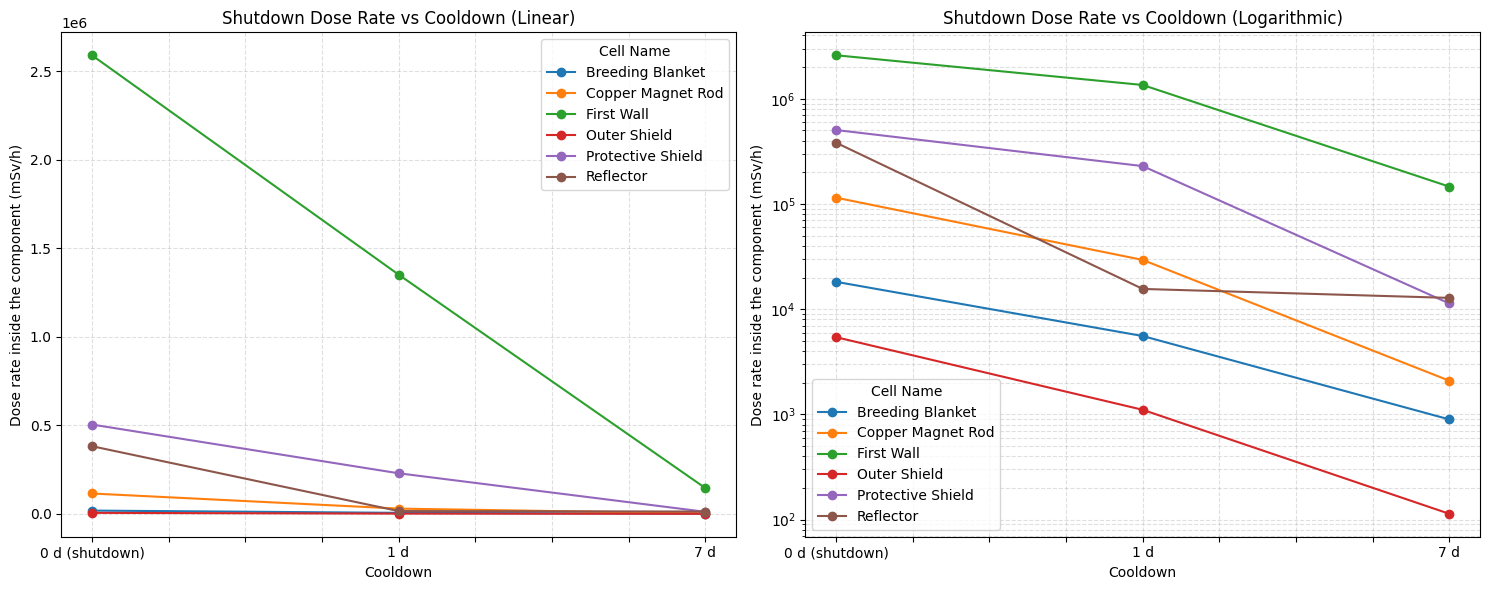

In [16]:
# Compare the three runs (shutdown_step = 1, 2, 3)  -> 0 d, 1 d, 7 d after shutdown
labels = {1: '0 d (shutdown)', 2: '1 d', 3: '7 d'}
tables = []

# Loop through and extract the sddr_table.csv from each nested step folder inside SDDR_DIR
for step, lab in labels.items():
    step_folder = f"{MODEL_NAME}_SDDR_step{step}"
    p = os.path.join(SDDR_DIR, step_folder, 'sddr_table.csv')
    
    if os.path.exists(p):
        t = pd.read_csv(p)
        t['Cooldown'] = lab
        tables.append(t)

df_cd = pd.concat(tables)
pivot = df_cd.pivot(index='Cell Name', columns='Cooldown', values='Dose Rate (mSv/hr)')[[l for l in labels.values() if l in df_cd['Cooldown'].values]]
display(pivot)

# Save the final comparison dataframe to the main SDDR_DIR
comparison_csv_path = os.path.join(SDDR_DIR, 'SDDR_comparison.csv')
pivot.to_csv(comparison_csv_path)
print(f"Comparison CSV saved to {comparison_csv_path}")

# Generate a 1-row, 2-column figure layout for side-by-side plotting
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Left Subplot: Non-Logarithmic (Linear) Scale
pivot.T.plot(ax=axes[0], logy=False, marker='o')
axes[0].set_ylabel('Dose rate inside the component (mSv/h)')
axes[0].set_title('Shutdown Dose Rate vs Cooldown (Linear)')
axes[0].grid(True, which='major', ls='--', alpha=0.4)

# Right Subplot: Logarithmic Scale
pivot.T.plot(ax=axes[1], logy=True, marker='o')
axes[1].set_ylabel('Dose rate inside the component (mSv/h)')
axes[1].set_title('Shutdown Dose Rate vs Cooldown (Logarithmic)')
axes[1].grid(True, which='both', ls='--', alpha=0.4)

# Adjust layout to prevent overlap and save the dual-plot figure in SDDR_DIR
plt.tight_layout()
plot_path = os.path.join(SDDR_DIR, 'SDDR_cooldown_comparison.png')
plt.savefig(plot_path, dpi=300, bbox_inches='tight')
print(f"Comparison plot saved to {plot_path}")
plt.show()